In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
x = pd.read_csv('x.csv', index_col=0)
y = pd.read_csv('y.csv', index_col=0)

In [ ]:
type(x)

pandas.core.frame.DataFrame

In [ ]:
type(x.values)

numpy.ndarray

# **Задача 3**

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
    def fit(self, X, Y, alpha=0.1, accuracy=0.01, max_steps=5000):
        steps, errors = [], []
        step = 0
        for _ in range(4000):
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= alpha * dJ0
            self.b1 -= alpha * dJ1
            new_err = self.error(X, Y)
            step += 1
            steps.append(step)
            errors.append(new_err)
        return steps, errors

error after gradient descent: [1.65862443e-27]


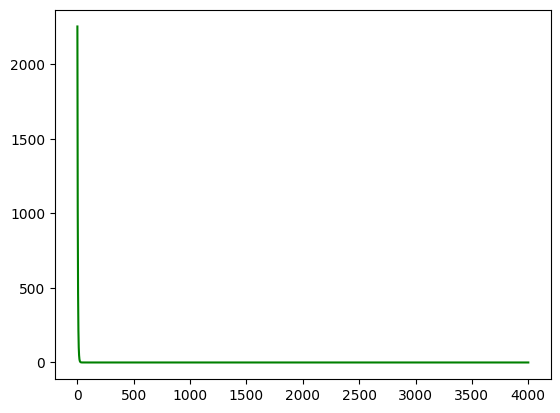

In [ ]:
hyp = Model()
steps, errors = hyp.fit(x, y)
J = hyp.error(x, y)
print("error after gradient descent:", J)
plt.figure()
plt.plot(steps, errors, 'g')
plt.show()

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return ((self.predict(X) - Y)**2).sum() / (2 * len(X))
    def fit(self, X, Y, alpha=0.1, accuracy=0.01, max_steps=5000):
        steps, errors = [], []
        step = 0
        for _ in range(4000):
            dJ0 = (self.predict(X) - Y).sum() /len(X)
            dJ1 = ((self.predict(X) - Y) * X).sum() /len(X)
            self.b0 -= alpha * dJ0
            self.b1 -= alpha * dJ1
            new_err = self.error(X, Y)
            step += 1
            steps.append(step)
            errors.append(new_err)
        return steps, errors

error after gradient descent: 0    1.658624e-27
dtype: float64


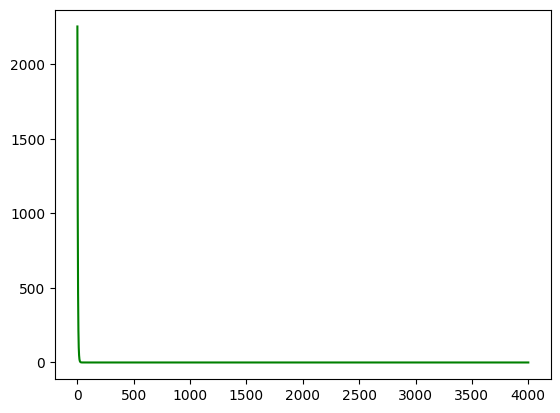

In [ ]:
hyp = Model()
steps, errors = hyp.fit(x, y)
J = hyp.error(x, y)
print("error after gradient descent:", J)
plt.figure()
plt.plot(steps, errors, 'g')
plt.show()

# **Задачи 4 и 5**

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
    def fit(self, X, Y, alpha=0.001, accuracy=1e-6, max_steps=5000):
        steps, errors = [], []
        step = 0
        old_err = self.error(X, Y)
        for _ in range(max_steps):
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= alpha * dJ0
            self.b1 -= alpha * dJ1
            new_err = self.error(X, Y)
            if abs(new_err - old_err) < accuracy:
              break
            step += 1
            steps.append(step)
            errors.append(new_err)
            old_err = new_err
        return steps, errors


# **Задача 6**

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
        self.alpha = 0.1
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):
        steps, errors = [], []
        step = 0
        old_err = np.inf
        for _ in range(max_steps):
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= self.alpha * dJ0
            self.b1 -= self.alpha * dJ1
            new_err = self.error(X, Y)
            if abs(new_err - old_err) < accuracy:
              break
            if abs(new_err) >= abs(old_err):
              self.alpha /= 2
              print(self.alpha)
              self.b0 = 0
              self.b1 = 0
            step += 1
            steps.append(step)
            errors.append(new_err)
            old_err = new_err
        return steps, errors


# **Задача 7**

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
        self.alpha = 0.1
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
    def plotGraph(self, X, Y):
        X0 = np.linspace(X.min(), X.max(), 100)
        Y0 = self.predict(X0)
        plt.figure()
        plt.scatter(X, Y)
        plt.plot(X0, Y0, 'r')
        plt.show()
    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):
        steps, errors = [], []
        step = 0
        old_err = np.inf
        for _ in range(max_steps):
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= self.alpha * dJ0
            self.b1 -= self.alpha * dJ1
            new_err = self.error(X, Y)
            if abs(new_err - old_err) < accuracy:
              break
            step += 1
            steps.append(step)
            errors.append(new_err)
            old_err = new_err
        return steps, errors


In [ ]:
hyp = Model()
steps, errors = hyp.fit(x, y)
J = hyp.error(x, y)
print("error after gradient descent:", J)

error after gradient descent: [4.34165671e-06]


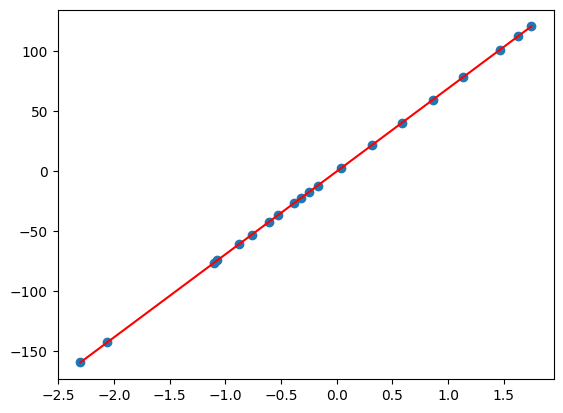

In [ ]:
hyp.plotGraph(x.values, y.values)

# **Задача 1 из доп.**

/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


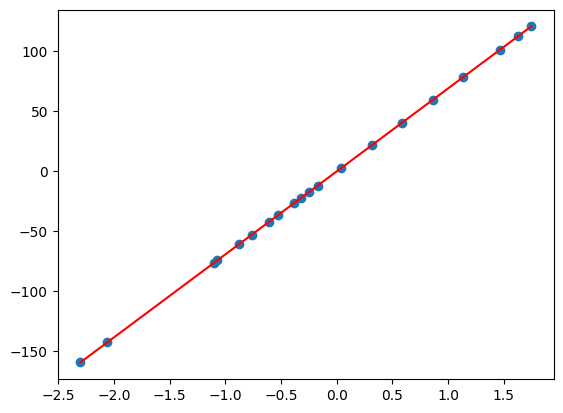

In [ ]:
from sklearn.linear_model import LinearRegression

model_sklearn = LinearRegression()
model_sklearn.fit(x, y)

X0 = np.linspace(x.min(), x.max(), 100)
Y0 = model_sklearn.predict(X0)
plt.figure()
plt.scatter(x, y)
plt.plot(X0, Y0, 'r')

# **Задача 2 из доп.**

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
        self.alpha = 0.1
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
    def plotGraph(self, X, Y):
        X0 = np.linspace(X.min(), X.max(), 100)
        Y0 = self.predict(X0)
        plt.figure()
        plt.scatter(X, Y)
        plt.plot(X0, Y0, 'r')
        plt.show()
    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):
        steps, errors = [], []
        step = 0
        old_err = np.inf
        for _ in range(max_steps):
            dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            self.b0 -= self.alpha * dJ0
            self.b1 -= self.alpha * dJ1
            new_err = self.error(X, Y)
            if abs(new_err - old_err) < accuracy:
              break
            step += 1
            steps.append(step)
            errors.append(new_err)
            old_err = new_err
        return steps, errors
    def score(self, X, Y):
        y_pred = self.predict(X)
        ss_res = sum((Y - y_pred)**2)
        ss_total = sum((Y - np.mean(Y))**2)
        r2 = 1 - (ss_res / ss_total)
        return r2


# **Задача 3 из доп.**

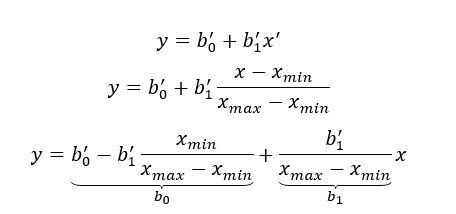

In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
        self.alpha = 0.1
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y).values**2) / (2 * len(X)))
    def plotGraph(self, X, Y):
        X0 = np.linspace(X.min(), X.max(), 100)
        Y0 = self.predict(X0)
        plt.figure()
        plt.scatter(X, Y)
        plt.plot(X0, Y0, 'r')
        plt.show()
    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):
        steps, errors = [], []
        step = 0
        old_err = np.inf

        X_normalized = (X - X.min())/(X.max() - X.min())
        for _ in range(max_steps):
            dJ0 = sum((self.predict(X_normalized) - Y).values) /len(X_normalized)
            dJ1 = sum(((self.predict(X_normalized) - Y) * X_normalized).values) /len(X_normalized)
            self.b0 -= self.alpha * dJ0
            self.b1 -= self.alpha * dJ1
            new_err = self.error(X_normalized, Y)
            if abs(new_err - old_err) < accuracy:
              break
            step += 1
            steps.append(step)
            errors.append(new_err)
            old_err = new_err
        self.b0 -= self.b1 * (X.min() / (X.max() - X.min())).values
        self.b1 /= (X.max() - X.min()).values
        return steps, errors

In [ ]:
hyp = Model()
steps, errors = hyp.fit(x, y)
J = hyp.error(x, y)
print("error after gradient descent:", J)

error after gradient descent: [8.69899405e-05]


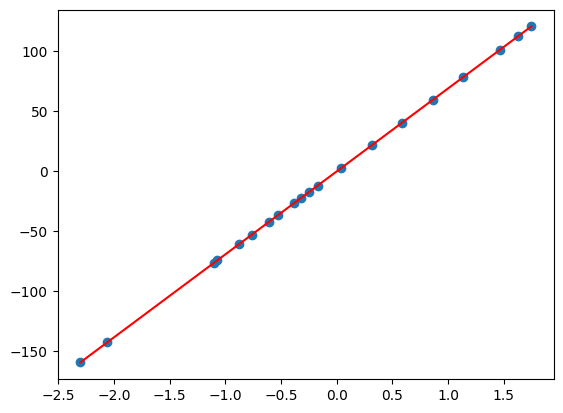

In [ ]:
# x_normalized = (x - x.min())/(x.max() - x.min())
X0 = np.linspace(x.min(), x.max(), 100)
Y0 = hyp.predict(X0)
plt.figure()
plt.scatter(x, y)
plt.plot(X0, Y0, 'r')